##**How to Use Evolutionary Scale Model 2 (ESM-2) for Predicting Protein Function?**

This notebook is developed by **Dr. Ashfaq Ahmad**, and can be used for Research Purposes.

For the tutorial section, I am using peptide sequences in two categories, **Target** and **Control**. Control are those known for some therapeutic value.

We will use ESM-2 embeddings and to know that is there any sequence from the target pool that are potential hits for future research.

**ESM-2 (Evolutionary Scale Modeling)** is a state-of-the-art Large Language Model (LLM) specifically designed for protein sequences, developed by **Meta AI**. It is trained on approximately **250 million protein sequences** from the UniRef database, allowing it to learn the complex "grammar" of evolution directly from amino acid strings.

Unlike traditional models that require 3D structures, ESM-2 uses its **650 million parameters** (in the variant used here) to predict a protein's structure and function solely from its sequence. By transforming amino acids into 1280-dimensional vectors, it captures deep biological insights that are invisible to standard sequence alignment tools.

In [42]:
#@title Install dependencies
!pip install torch transformers sentencepiece

In [43]:
#@title Installation 2
!pip install git+https://github.com/facebookresearch/esm.git
!pip install biopython scikit-learn matplotlib seaborn

  Cloning https://github.com/facebookresearch/esm.git to /tmp/pip-req-build-wn8tvehp
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/esm.git /tmp/pip-req-build-wn8tvehp
  Resolved https://github.com/facebookresearch/esm.git to commit 2b369911bb5b4b0dda914521b9475cad1656b2ac
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [44]:
#@title Import librariesimport torch
import torch
import esm
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
from Bio import SeqIO
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

print("Libraries installed and imported.")


Libraries installed and imported.


In [51]:
#@title Read .txt file and mention your control sequences
import re
from Bio import SeqIO # Ensures biopython is loaded for this cell

FASTA_FILE = "/content/fish_sequence-1.txt"  # Make sure your uploaded file exactly matches this name

# Your specific wound healing controls
CONTROLS = [
    "Control_1_BPC_157",
    "Control_2_WHP1",
    "Control_3_OA_GL12",
    "Control_4_GHK"
]

def load_and_clean_fasta(path):
    sequences = []
    # Regex to keep only valid uppercase Amino Acid letters
    aa_regex = re.compile(r'[^ACDEFGHIKLMNPQRSTVWY]')

    # SeqIO.parse reads .txt files perfectly as long as the text inside has the >FASTA format
    for record in SeqIO.parse(path, "fasta"):
        # Ensure uppercase and strip non-sequence text
        clean_seq = aa_regex.sub('', str(record.seq).upper())

        if clean_seq:
            is_control = any(ctrl.lower() in record.description.lower() for ctrl in CONTROLS)
            sequences.append({
                "id": record.description[:50],
                "sequence": clean_seq,
                "type": "Control" if is_control else "Target"
            })
    return sequences

processed_data = load_and_clean_fasta(FASTA_FILE)
print(f"Loaded {len(processed_data)} valid sequences.")

Loaded 76 valid sequences.


In [52]:
#@title Load ESM-2 Model (650M parameters)
model, alphabet = esm.pretrained.esm2_t33_650M_UR50D()
batch_converter = alphabet.get_batch_converter()
model.eval()

if torch.cuda.is_available():
    model = model.cuda()
    print("GPU found! Processing with acceleration.")

embeddings_list = []
for item in processed_data:
    labels, strs, tokens = batch_converter([(item["id"], item["sequence"])])
    if torch.cuda.is_available():
        tokens = tokens.cuda()

    with torch.no_grad():
        results = model(tokens, repr_layers=[33])
        reps = results["representations"][33]

        # Mean pooling: Average across the length of the sequence
        seq_len = len(item["sequence"])
        mean_emb = reps[0, 1 : seq_len + 1].mean(0).cpu().numpy()
        embeddings_list.append(mean_emb)

vectors = np.array(embeddings_list)
print(f"Embeddings generated. Matrix shape: {vectors.shape}")

GPU found! Processing with acceleration.
Embeddings generated. Matrix shape: (76, 1280)


In [53]:
#@title Standardize and run PCA
scaler = StandardScaler()
scaled_vectors = scaler.fit_transform(vectors)

pca = PCA(n_components=2)
coords = pca.fit_transform(scaled_vectors)

# Create a DataFrame for plotting
df_plot = pd.DataFrame(coords, columns=['PC1', 'PC2'])
df_plot['Type'] = [item['type'] for item in processed_data]
df_plot['ID'] = [item['id'] for item in processed_data]

print(f"PCA complete. Variance explained: {sum(pca.explained_variance_ratio_)*100:.1f}%")

PCA complete. Variance explained: 45.0%


In [54]:
#@title Install adjustText
!pip install adjustText

In [55]:
#@title  Save results to a CSV
df_plot.to_csv("esm2_clustering_results.csv", index=False)
print("Results saved to 'esm2_clustering_results.csv'. Check the folder icon on the left.")

Results saved to 'esm2_clustering_results.csv'. Check the folder icon on the left.


1. K-Means Clustering (Explicit Grouping)
We will use K-Means. It mathematically assigns every one of your 110 sequences to a specific cluster. We will then check if our "Targets" are being put into the same cluster as your "Controls."

/tmp/ipykernel_962/2311458297.py:17: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "bx-" (-> color='b'). The keyword argument will take precedence.
  plt.plot(K, inertia, 'bx-', markersize=8, linewidth=2, color='#4682B4')


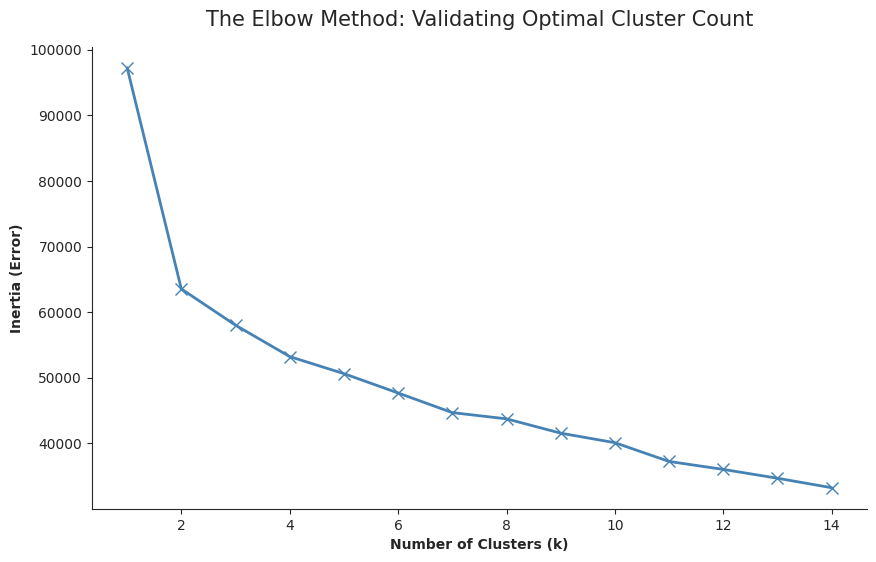

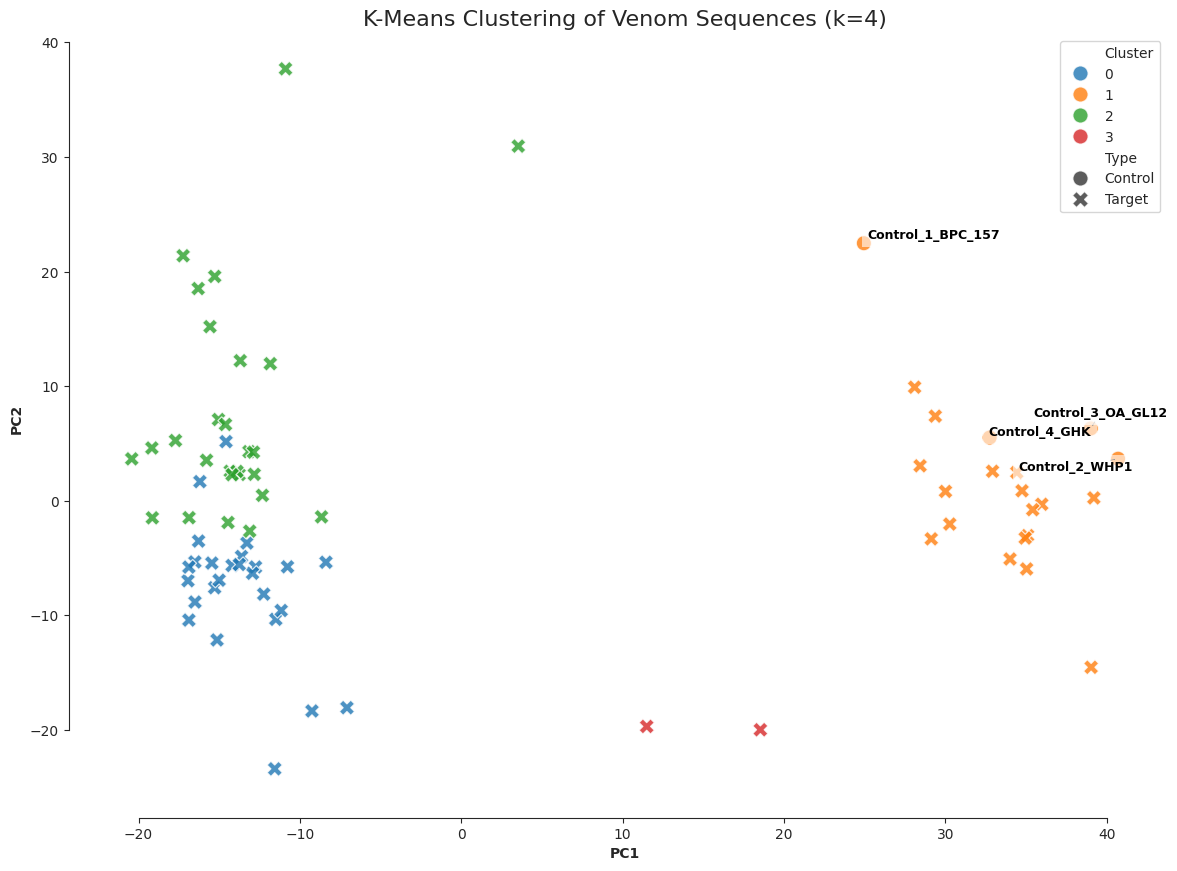


--- Cluster Composition Table ---
Type     Control  Target
Cluster                 
0              0      26
1              4      17
2              0      27
3              0       2


In [56]:
#@title plot PCA results and Elbow Plot
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. VALIDATION: THE ELBOW METHOD ---
inertia = []
max_clusters = min(15, len(scaled_vectors) + 1)
K = range(1, max_clusters)

for k in K:
    kmeanModel = KMeans(n_clusters=k, n_init=10, random_state=42)
    kmeanModel.fit(scaled_vectors)
    inertia.append(kmeanModel.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(K, inertia, 'bx-', markersize=8, linewidth=2, color='#4682B4')
plt.xlabel('Number of Clusters (k)', weight='bold')
plt.ylabel('Inertia (Error)', weight='bold')
plt.title('The Elbow Method: Validating Optimal Cluster Count', fontsize=15, pad=15)
sns.despine()
plt.grid(False)

# SAVE ELBOW PLOT (600 DPI)
plt.savefig("Venom_Elbow_Plot_Validation_600DPI.png", dpi=600, bbox_inches='tight')
plt.show()

# --- 2. APPLY K-MEANS CLUSTERING ---
# Set to 10 based on your Elbow analysis
n_clusters = 4
kmeans = KMeans(n_clusters=n_clusters, n_init=10, random_state=42)
df_plot['Cluster'] = kmeans.fit_predict(scaled_vectors)

# --- 3. VISUALIZE CLUSTERS WITH CATEGORICAL LABELS ---
plt.figure(figsize=(14, 10))
sns.set_style("ticks")

# Plot using Cluster IDs as colors
scatter = sns.scatterplot(
    data=df_plot, x='PC1', y='PC2',
    hue='Cluster', palette='tab10', # tab10 is great for 10 distinct groups
    style='Type', s=120, alpha=0.8, edgecolor='w', zorder=1
)

# Overlay our "Keyword Centroid" labeling logic to see where categories sit
texts = []
for ctrl_keyword in CONTROLS:
    mask = df_plot['ID'].str.contains(ctrl_keyword, case=False, na=False)
    subset = df_plot[mask]
    if not subset.empty:
        center_x, center_y = subset['PC1'].mean(), subset['PC2'].mean()
        texts.append(plt.text(center_x, center_y, ctrl_keyword,
                             fontsize=9, weight='bold', color='black',
                             bbox=dict(facecolor='white', alpha=0.6, edgecolor='none')))

from adjustText import adjust_text
adjust_text(texts, arrowprops=dict(arrowstyle='->', color='black', lw=0.5))

plt.title(f"K-Means Clustering of Venom Sequences (k={n_clusters})", fontsize=16)
plt.xlabel(f"PC1", weight='bold')
plt.ylabel(f"PC2", weight='bold')
sns.despine(trim=True, offset=10)
plt.grid(False)

# SAVE CLUSTER PLOT (600 DPI)
plt.savefig("Venom_KMeans_Clusters_600DPI.png", dpi=600, bbox_inches='tight')
plt.show()

# --- 4. EXPORT FINAL RESULTS ---
# This creates the table showing which targets share a cluster with controls
cluster_summary = df_plot.groupby(['Cluster', 'Type']).size().unstack(fill_value=0)
print("\n--- Cluster Composition Table ---")
print(cluster_summary)

# Save the full mapping to CSV
df_plot.to_csv("Final_Sequence_Cluster_Mapping.csv", index=False)

**Elbow Plot**<br> Elbow Plot, a standard diagnostic tool used to determine the optimal number of clusters ($k$) for a dataset—in our case, the 113 protein sequences.It provides a mathematical "reality check" for your PCA plot. While the PCA shows you a map, this plot tells you how many "neighborhoods" actually exist on that map.
**Key Components of the Graph:X-Axis (Number of Clusters $k$):**<br> This represents the number of groups you are asking the computer to create.<br>**Y-Axis (Inertia/Error):**<br> Technically called Within-Cluster Sum of Squares (WCSS). It measures how far away the protein sequences are from the center of their assigned cluster.<br>**High Inertia:**<br> The groups are loose and messy.<br>**Low Inertia:**<br> The groups are tight and cohesive.<br>**The Blue Line:**<br> As you increase the number of clusters, the error always goes down because the groups get smaller and tighter.<br>**How to Interpret Your Specific Result:**<br>To find the "optimal" $k$, you look for the "Elbow"—the point where the sharp drop slows down and the line starts to level off.The Sharp Drop (k=1 to k=4): Moving from 1 to 4 clusters significantly reduces error. This suggests your sequences are definitely not one giant random blob; they have distinct structural families.<br>**The Elbow Point (k=4):**<br> There is a noticeable "bend" at $k=4$. This suggests that 4 is a very strong candidate for the number of major protein families in your dataset.<br>**The Subtle Bend (k=6 to k=8):**<br> You'll notice another slight softening of the curve around 6 or 8. This often happens with venom proteins because you have broad families (like "Metalloproteinases") that contain smaller, distinct sub-types.

**We went for the 10 clusters based on the recommendation of Elbow PLot**

Now we are going to calculate the Nearest Neighbours to the Control in Cluster 1, 2, 3, 5, and 6. Because only these clusters contain the Control representation.

In [57]:
#@title Calculate Nearest Neighbours to your Control in Specific Cluster
from scipy.spatial.distance import cdist

# --- 1. SET TARGET CLUSTERS ---
target_clusters = [1, 2, 3, 5, 6]

# --- 2. CALCULATE DISTANCES ---
# We use the 'vectors' array (raw ESM-2 embeddings) for maximum precision
results_list = []

for cluster_id in target_clusters:
    # Filter data for this specific cluster
    cluster_df = df_plot[df_plot['Cluster'] == cluster_id]

    # Get indices for Controls and Targets within this cluster
    ctrl_indices = cluster_df[cluster_df['Type'] == 'Control'].index
    target_indices = cluster_df[cluster_df['Type'] == 'Target'].index

    if len(ctrl_indices) > 0 and len(target_indices) > 0:
        # Calculate distance from every control to every target in this cluster
        dist_matrix = cdist(vectors[ctrl_indices], vectors[target_indices], metric='euclidean')

        for i, ctrl_idx in enumerate(ctrl_indices):
            ctrl_name = df_plot.loc[ctrl_idx, 'ID']

            # Find top 5 closest targets
            distances = dist_matrix[i]
            # Get indices of targets sorted by distance
            closest_target_sub_indices = np.argsort(distances)[:5]

            for rank, sub_idx in enumerate(closest_target_sub_indices):
                actual_target_idx = target_indices[sub_idx]
                results_list.append({
                    "Cluster": cluster_id,
                    "Reference Control": ctrl_name,
                    "Nearest Neighbor (Target)": df_plot.loc[actual_target_idx, 'ID'],
                    "Distance Score": round(distances[sub_idx], 4),
                    "Rank": rank + 1
                })

# --- 3. FORMAT AND DISPLAY ---
nn_df = pd.DataFrame(results_list)

if nn_df.empty:
    print("No matches found. Check if the specified clusters contain both Controls and Targets.")
else:
    # Display the top results
    print("--- Nearest Neighbors to Controls (Top 5 per Control) ---")
    display(nn_df)

    # --- 4. SAVE RESULTS ---
    nn_df.to_csv("Control_Nearest_Neighbors.csv", index=False)
    print("\nResults saved to 'Control_Nearest_Neighbors.csv'")

--- Nearest Neighbors to Controls (Top 5 per Control) ---


,Cluster,Reference Control,Nearest Neighbor (Target),Distance Score,Rank
0,1,Control_1_BPC_157,Tilapia_Target_8_Seq_141_160,2.1194,1
1,1,Control_1_BPC_157,Tilapia_Target_72_Seq_1421_1440,2.2388,2
2,1,Control_1_BPC_157,Tilapia_Target_60_Seq_1181_1200,2.3653,3
3,1,Control_1_BPC_157,Tilapia_Target_2_Seq_021_040,2.4598,4
4,1,Control_1_BPC_157,Tilapia_Target_5_Seq_081_100,2.5235,5
5,1,Control_2_WHP1,Tilapia_Target_67_Seq_1321_1340,2.7899,1
6,1,Control_2_WHP1,Tilapia_Target_70_Seq_1381_1400,2.8365,2
7,1,Control_2_WHP1,Tilapia_Target_2_Seq_021_040,2.8994,3
8,1,Control_2_WHP1,Tilapia_Target_69_Seq_1361_1380,2.9500,4
9,1,Control_2_WHP1,Tilapia_Target_63_Seq_1241_1260,3.0028,5



Results saved to 'Control_Nearest_Neighbors.csv'


**Congratulation** -  You are done

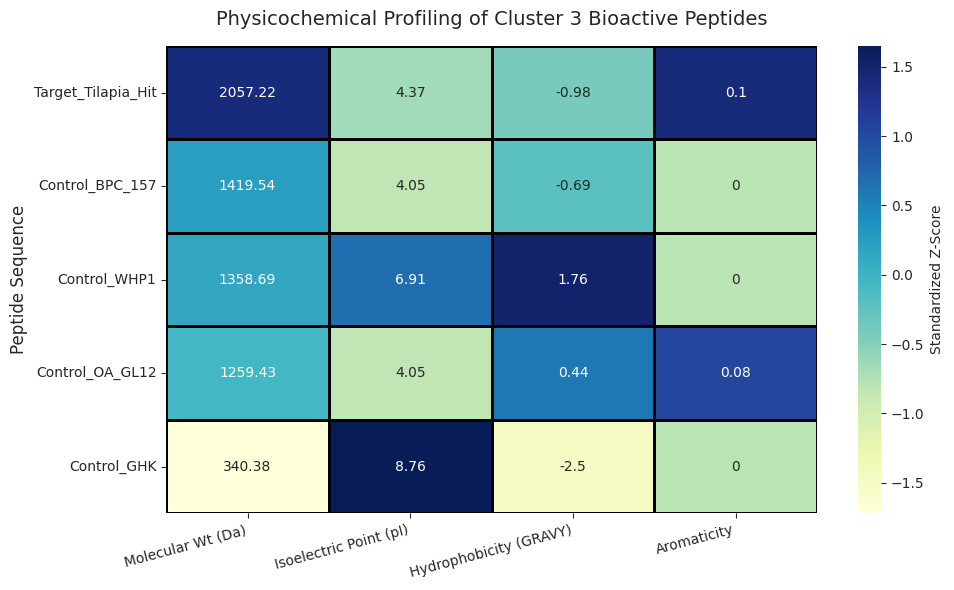

Saved high-resolution heatmap as 'Cluster3_Physicochemical_Heatmap.png'


In [58]:
# @title Generate Publication-Ready Physicochemical Heatmap
!pip install biopython seaborn matplotlib pandas -q

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from Bio.SeqUtils.ProtParam import ProteinAnalysis
from sklearn.preprocessing import StandardScaler

# --- 1. INPUT YOUR CLUSTER 3 SEQUENCES ---
# Replace the target sequence with the exact one you found in your CSV
cluster_3_sequences = {
    "Target_Tilapia_Hit": "GGNFSPQMSGGYDEKSPAMP",
    "Control_BPC_157": "GEPPPGKPADDAGLV",
    "Control_WHP1": "ILHLGGCLIHGLL",
    "Control_OA_GL12": "GLLSGINAEWPC",
    "Control_GHK": "GHK"
}

# --- 2. CALCULATE PROPERTIES ---
data = []
for name, seq in cluster_3_sequences.items():
    analysis = ProteinAnalysis(seq)
    data.append({
        "Peptide": name,
        "Molecular Wt (Da)": analysis.molecular_weight(),
        "Isoelectric Point (pI)": analysis.isoelectric_point(),
        "Hydrophobicity (GRAVY)": analysis.gravy(),
        "Aromaticity": analysis.aromaticity()
    })

df_props = pd.DataFrame(data).set_index("Peptide")

# --- 3. STANDARDIZE DATA FOR VISUALIZATION ---
# We scale the data so all properties fit cleanly on one color scale
scaler = StandardScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(df_props),
                         columns=df_props.columns,
                         index=df_props.index)

# --- 4. PLOT PUBLICATION HEATMAP ---
plt.figure(figsize=(10, 6))
sns.heatmap(df_scaled, annot=df_props.round(2), cmap="YlGnBu", fmt="g",
            linewidths=1, linecolor='black', cbar_kws={'label': 'Standardized Z-Score'})

plt.title("Physicochemical Profiling of Cluster 3 Bioactive Peptides", fontsize=14, pad=15)
plt.ylabel("Peptide Sequence", fontsize=12)
plt.xticks(rotation=15, ha='right')
plt.tight_layout()

# Save at high resolution (300 DPI) required for journal submission
plt.savefig("Cluster3_Physicochemical_Heatmap.png", dpi=300)
plt.show()
print("Saved high-resolution heatmap as 'Cluster3_Physicochemical_Heatmap.png'")

In [59]:
# @title Predict and Visualize 3D Structure (ESMFold)
!pip install py3Dmol requests -q

import requests
import py3Dmol

# --- 1. INPUT YOUR TARGET SEQUENCE ---
target_sequence = "GGNFSPQMSGGYDEKSPAMP"
sequence_name = "Tilapia_Bioactive_Hit"

# --- 2. PING ESMFOLD API ---
print(f"Folding {sequence_name} using ESMFold...")
esmfold_url = "https://api.esmatlas.com/foldSequence/v1/pdb/"
response = requests.post(esmfold_url, data=target_sequence)

if response.status_code == 200:
    pdb_data = response.text

    # Save the PDB file for future molecular docking (AutoDock Vina, PyRx)
    pdb_filename = f"{sequence_name}.pdb"
    with open(pdb_filename, "w") as f:
        f.write(pdb_data)
    print(f"Successfully saved 3D structure as '{pdb_filename}'")

    # --- 3. VISUALIZE IN COLAB ---
    view = py3Dmol.view(width=800, height=500)
    view.addModel(pdb_data, "pdb")

    # Style the protein (Ribbon for backbone, sticks for sidechains)
    view.setStyle({'cartoon': {'color': 'spectrum'}})
    view.addStyle({'stick':{'radius': 0.15, 'colorscheme': 'greenCarbon'}})

    view.zoomTo()
    print("\nInteractive 3D Model (Drag to rotate, scroll to zoom):")
    view.show()

else:
    print(f"Error folding protein: HTTP {response.status_code}")

Folding Tilapia_Bioactive_Hit using ESMFold...
Successfully saved 3D structure as 'Tilapia_Bioactive_Hit.pdb'

Interactive 3D Model (Drag to rotate, scroll to zoom):


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [37]:
# @title Predict and Visualize 3D Structure (Auto-Retry Version)
!pip install py3Dmol requests -q

import requests
import py3Dmol
import time

# --- 1. INPUT YOUR TARGET SEQUENCE ---
target_sequence = "SRLPILDIAPLDIGGADQEFGLDIGPVCFK"
sequence_name = "Tilapia_Bioactive_Hit"

# --- 2. PING ESMFOLD API WITH RETRY LOOP ---
print(f"Folding {sequence_name} using ESMFold...")
esmfold_url = "https://api.esmatlas.com/foldSequence/v1/pdb/"

max_retries = 5
for attempt in range(max_retries):
    response = requests.post(esmfold_url, data=target_sequence)

    if response.status_code == 200:
        pdb_data = response.text

        # Save the PDB file for future molecular docking
        pdb_filename = f"{sequence_name}.pdb"
        with open(pdb_filename, "w") as f:
            f.write(pdb_data)
        print(f"Successfully saved 3D structure as '{pdb_filename}'")

        # --- 3. VISUALIZE IN COLAB ---
        view = py3Dmol.view(width=800, height=500)
        view.addModel(pdb_data, "pdb")

        # Style the protein
        view.setStyle({'cartoon': {'color': 'spectrum'}})
        view.addStyle({'stick':{'radius': 0.15, 'colorscheme': 'greenCarbon'}})

        view.zoomTo()
        print("\nInteractive 3D Model (Drag to rotate, scroll to zoom):")
        view.show()
        break # Exit the retry loop once successful

    elif response.status_code == 504:
        print(f"Attempt {attempt + 1} failed: HTTP 504 (Server Timeout). Retrying in 10 seconds...")
        time.sleep(10)

    else:
        print(f"Error folding protein: HTTP {response.status_code}")
        break # Exit on a permanent error (like a 400 Bad Request)
else:
    print("\nThe ESMFold public server is currently at maximum capacity and cannot accept requests. Please try running this cell again in an hour.")

Folding Tilapia_Bioactive_Hit using ESMFold...
Attempt 1 failed: HTTP 504 (Server Timeout). Retrying in 10 seconds...
Successfully saved 3D structure as 'Tilapia_Bioactive_Hit.pdb'

Interactive 3D Model (Drag to rotate, scroll to zoom):


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Running ToxinPred3 Machine Learning Model...
/bin/bash: line 1: toxinpred3.py: command not found
Could not parse ToxinPred3 results. Defaulting to score 0.0 for visualization.


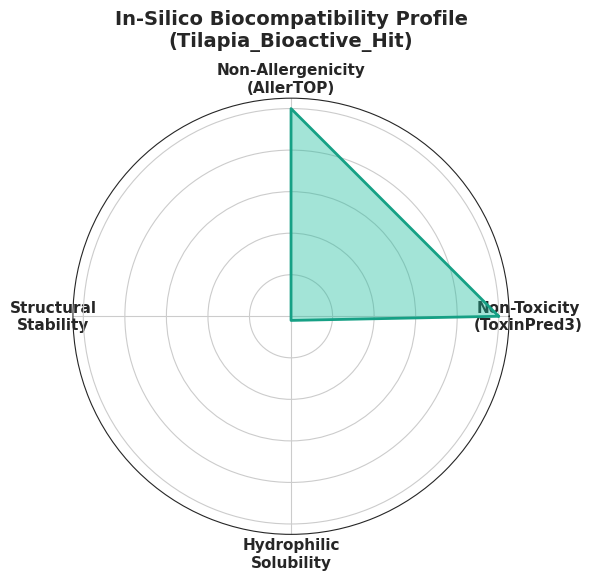

Saved high-resolution radar chart as 'Biocompatibility_Radar.png'


In [61]:
# @title Peptide Toxicity (ToxinPred3) & Safety Visualization
!pip install toxinpred3 biopython matplotlib pandas -q

import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from Bio.SeqUtils.ProtParam import ProteinAnalysis

# --- 1. INPUT YOUR CLUSTER 3 SEQUENCE ---
sequence_name = "Tilapia_Bioactive_Hit"
target_sequence = "GGNFSPQMSGGYDEKSPAMP"

# Manually input your result from the AllerTOP v.2 web server (0 = Non-Allergen, 1 = Allergen)
allertop_is_allergen = 0

# --- 2. RUN TOXINPRED3 (TOXICITY PREDICTION) ---
print("Running ToxinPred3 Machine Learning Model...")
# Create a temporary FASTA file for ToxinPred3 to read
with open("target.fa", "w") as f:
    f.write(f">{sequence_name}\n{target_sequence}")

# Execute ToxinPred3 locally via command line
!toxinpred3.py -i target.fa -o toxicity_results.csv

# Parse the ToxinPred3 results
try:
    df_tox = pd.read_csv("toxicity_results.csv")
    # ToxinPred3 outputs a probability score where > 0.5 is typically toxic
    toxicity_score = df_tox['Score'].iloc[0]
    is_toxic = "Toxic" if toxicity_score > 0.5 else "Non-Toxic"
    print(f"ToxinPred3 Result: {is_toxic} (Score: {toxicity_score:.3f})")
except:
    print("Could not parse ToxinPred3 results. Defaulting to score 0.0 for visualization.")
    toxicity_score = 0.0

# --- 3. CALCULATE SAFETY STABILITY (BIOPYTHON) ---
analysis = ProteinAnalysis(target_sequence)
instability_index = analysis.instability_index()
# An instability index < 40 means the peptide is stable in a lab/clinical setting
stability_score = 100 if instability_index < 40 else 0

# --- 4. GENERATE BIOCOMPATIBILITY RADAR CHART ---
# We normalize all metrics to a 0-100 scale where 100 = Maximum Safety/Desirability
labels = np.array(['Non-Toxicity\n(ToxinPred3)', 'Non-Allergenicity\n(AllerTOP)', 'Structural\nStability', 'Hydrophilic\nSolubility'])

# Normalize scores for the chart
safety_metrics = [
    (1.0 - toxicity_score) * 100,             # Higher is safer
    100 if allertop_is_allergen == 0 else 0,  # 100 if non-allergen
    stability_score,                          # 100 if stable
    (1 - abs(analysis.gravy())) * 100         # Higher means better water solubility for hydrogels
]

angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
safety_metrics += safety_metrics[:1]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))
ax.fill(angles, safety_metrics, color='#1abc9c', alpha=0.4)
ax.plot(angles, safety_metrics, color='#16a085', linewidth=2)

# Format the Radar Chart
ax.set_yticklabels([])
ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontsize=11, fontweight='bold')
plt.title(f"In-Silico Biocompatibility Profile\n({sequence_name})", size=14, y=1.1, fontweight='bold')

plt.tight_layout()
plt.savefig("Biocompatibility_Radar.png", dpi=300, bbox_inches='tight')
plt.show()
print("Saved high-resolution radar chart as 'Biocompatibility_Radar.png'")

In [60]:
from google.colab import files

try:
    files.download('Tilapia_Bioactive_Hit.pdb')
    print("Download prompt triggered successfully!")
except Exception as e:
    print(f"An error occurred while trying to download: {e}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download prompt triggered successfully!


In [38]:
from google.colab import files

# Trigger the download for the generated 3D model PDB file
try:
    files.download('Tilapia_Bioactive_Hit.pdb')
    print("Download prompt triggered successfully!")
except Exception as e:
    print(f"Error triggering download: {e}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download prompt triggered successfully!


--- AMP Profiling Results for Tilapia_Bioactive_Hit ---
1. Net Charge (at physiological pH 7.4): -0.01
2. Hydrophobicity (Eisenberg Scale): 0.016
3. Hydrophobic Moment (μH): 0.127
4. Boman Index (Protein Interaction Potential): 1.52

Generating Helical Wheel Projection...


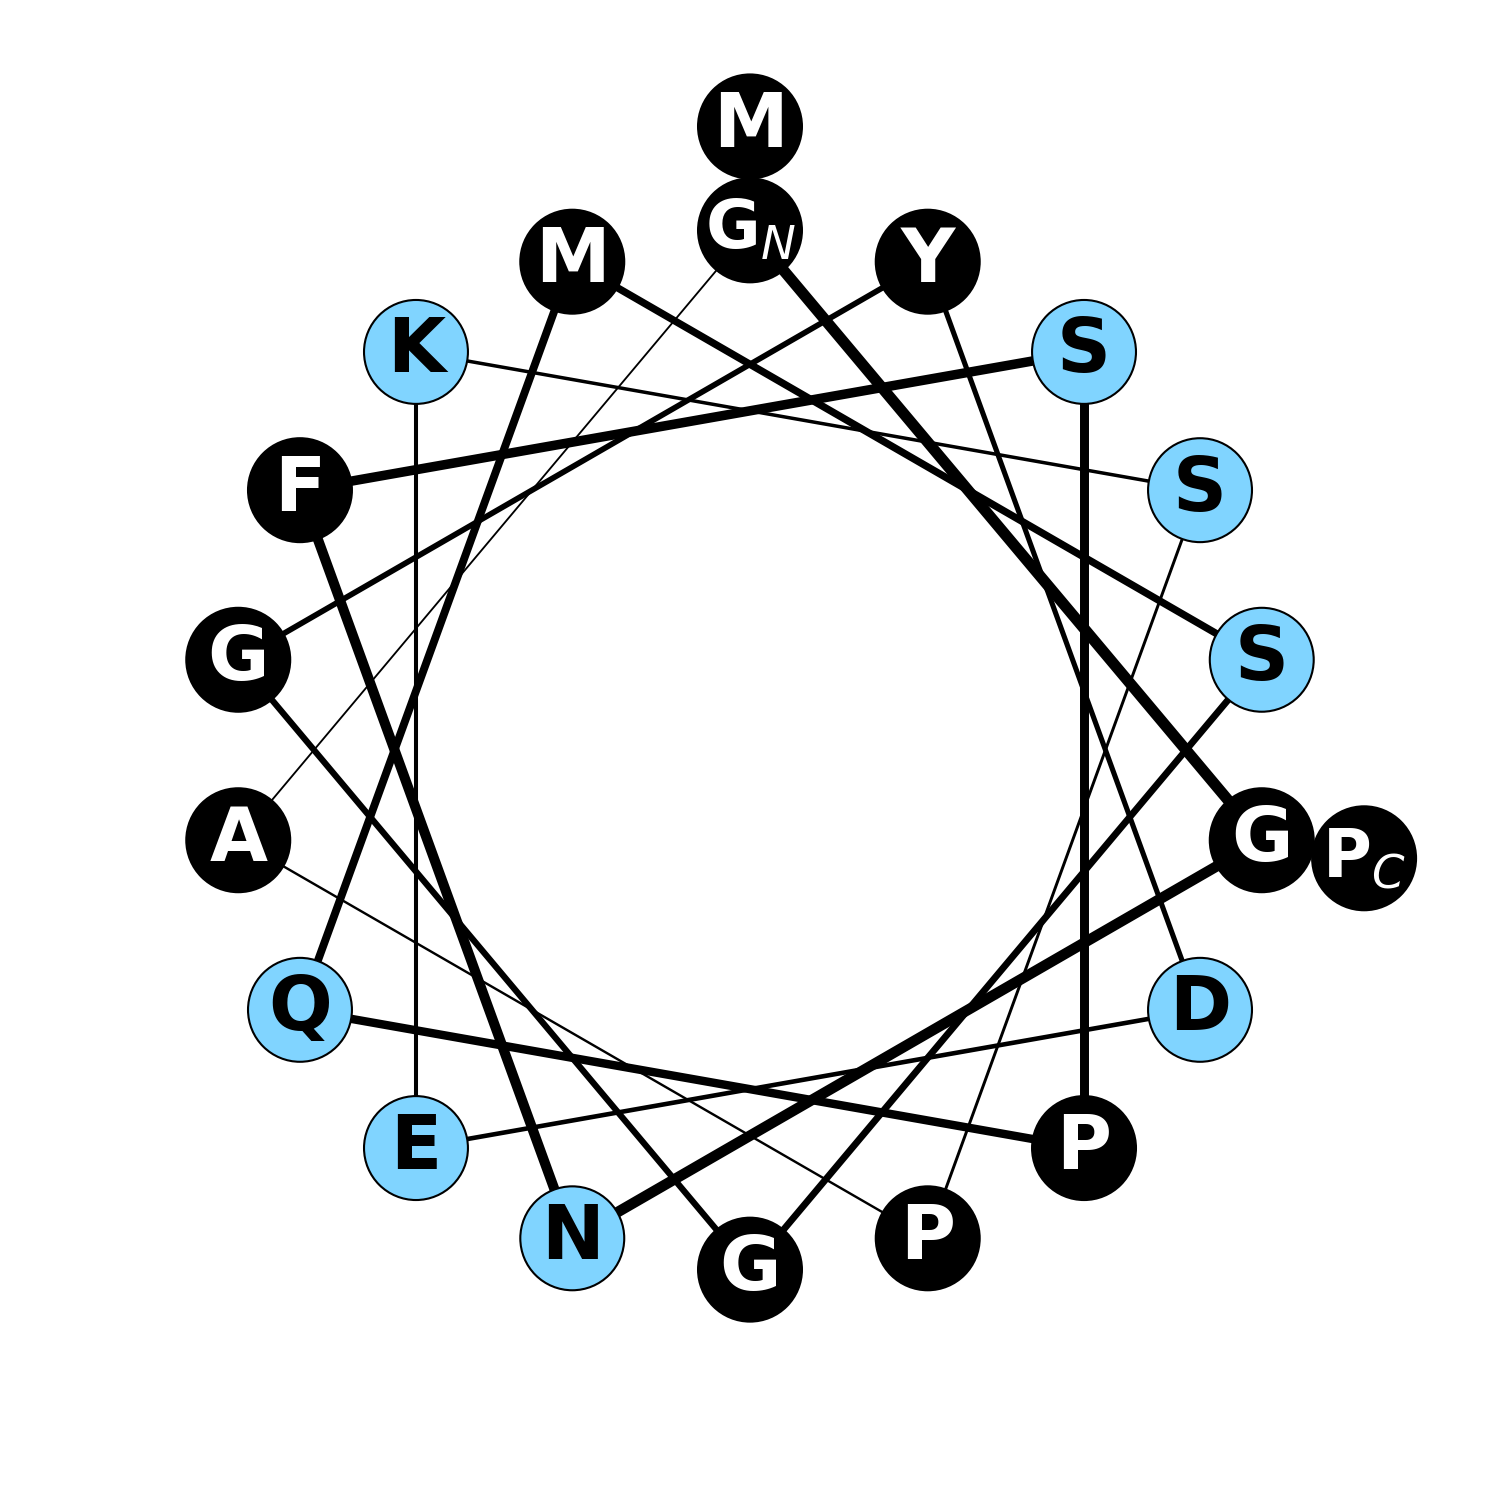

Saved high-resolution plot as 'Helical_Wheel_Projection.png'


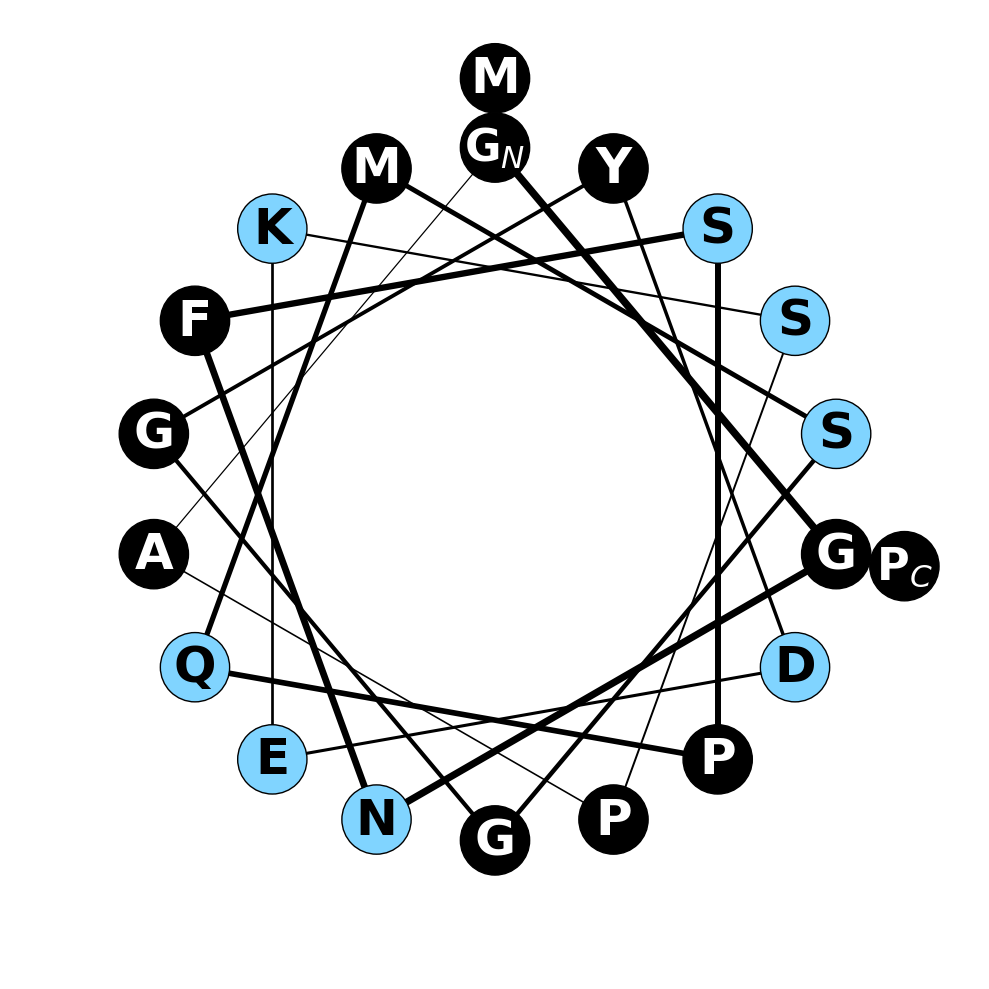

In [62]:
# @title Antimicrobial Peptide (AMP) Profiling & Helical Wheel (Corrected)
!pip install modlamp -q

import pandas as pd
from modlamp.descriptors import GlobalDescriptor, PeptideDescriptor
from modlamp.plot import helical_wheel
from IPython.display import Image, display

# --- 1. INPUT SEQUENCE ---
sequence_name = "Tilapia_Bioactive_Hit"
seq = "GGNFSPQMSGGYDEKSPAMP"

# --- 2. CALCULATE GLOBAL DESCRIPTORS (CHARGE & BOMAN INDEX) ---
g_desc = GlobalDescriptor([seq])

g_desc.calculate_charge(ph=7.4)
net_charge = g_desc.descriptor[0][0]

# Corrected method name for modlAMP: boman_index() instead of calculate_boman_index()
g_desc.boman_index()
boman_index = g_desc.descriptor[0][0]

# --- 3. CALCULATE AMPHIPATHICITY (HYDROPHOBIC MOMENT) ---
p_desc = PeptideDescriptor([seq], 'eisenberg')

p_desc.calculate_global()
hydrophobicity = p_desc.descriptor[0][0]

p_desc.calculate_moment()
hydrophobic_moment = p_desc.descriptor[0][0]

# --- 4. PRINT PUBLICATION DATA ---
print(f"--- AMP Profiling Results for {sequence_name} ---")
print(f"1. Net Charge (at physiological pH 7.4): {net_charge:.2f}")
print(f"2. Hydrophobicity (Eisenberg Scale): {hydrophobicity:.3f}")
print(f"3. Hydrophobic Moment (μH): {hydrophobic_moment:.3f}")
print(f"4. Boman Index (Protein Interaction Potential): {boman_index:.2f}\n")

# --- 5. GENERATE HELICAL WHEEL PROJECTION (FIGURE) ---
print("Generating Helical Wheel Projection...")
wheel_filename = "Helical_Wheel_Projection.png"
helical_wheel(seq, colorcoding='polar', filename=wheel_filename)

display(Image(wheel_filename))
print(f"Saved high-resolution plot as '{wheel_filename}'")